## Import libraries

In [4]:
import os
import sys

if os.path.basename(os.getcwd()) == 'notebooks':
    os.chdir('..')

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from helper.helper import load_data

In [6]:
data_path = 'data/original/SeoulBikeData.csv'
df = load_data(data_path)
df

,Date,Rented Bike Count,Hour,Temperature(°C),Humidity(%),Wind speed (m/s),Visibility (10m),Dew point temperature(°C),Solar Radiation (MJ/m2),Rainfall(mm),Snowfall (cm),Seasons,Holiday,Functioning Day
0,01/12/2017,254,0,-5.2,37,2.2,2000,-17.6,0.0,0.0,0.0,Winter,No Holiday,Yes
1,01/12/2017,204,1,-5.5,38,0.8,2000,-17.6,0.0,0.0,0.0,Winter,No Holiday,Yes
2,01/12/2017,173,2,-6.0,39,1.0,2000,-17.7,0.0,0.0,0.0,Winter,No Holiday,Yes
3,01/12/2017,107,3,-6.2,40,0.9,2000,-17.6,0.0,0.0,0.0,Winter,No Holiday,Yes
4,01/12/2017,78,4,-6.0,36,2.3,2000,-18.6,0.0,0.0,0.0,Winter,No Holiday,Yes
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
8755,30/11/2018,1003,19,4.2,34,2.6,1894,-10.3,0.0,0.0,0.0,Autumn,No Holiday,Yes
8756,30/11/2018,764,20,3.4,37,2.3,2000,-9.9,0.0,0.0,0.0,Autumn,No Holiday,Yes
8757,30/11/2018,694,21,2.6,39,0.3,1968,-9.9,0.0,0.0,0.0,Autumn,No Holiday,Yes
8758,30/11/2018,712,22,2.1,41,1.0,1859,-9.8,0.0,0.0,0.0,Autumn,No Holiday,Yes


## Exploratory data analysis

In [7]:
df.shape

(8760, 14)

In [8]:
df.columns

Index(['Date', 'Rented Bike Count', 'Hour', 'Temperature(°C)', 'Humidity(%)',
       'Wind speed (m/s)', 'Visibility (10m)', 'Dew point temperature(°C)',
       'Solar Radiation (MJ/m2)', 'Rainfall(mm)', 'Snowfall (cm)', 'Seasons',
       'Holiday', 'Functioning Day'],
      dtype='str')

In [13]:
df.head()

,Date,Rented Bike Count,Hour,Temperature(°C),Humidity(%),Wind speed (m/s),Visibility (10m),Dew point temperature(°C),Solar Radiation (MJ/m2),Rainfall(mm),Snowfall (cm),Seasons,Holiday,Functioning Day
0,01/12/2017,254,0,-5.2,37,2.2,2000,-17.6,0.0,0.0,0.0,Winter,No Holiday,Yes
1,01/12/2017,204,1,-5.5,38,0.8,2000,-17.6,0.0,0.0,0.0,Winter,No Holiday,Yes
2,01/12/2017,173,2,-6.0,39,1.0,2000,-17.7,0.0,0.0,0.0,Winter,No Holiday,Yes
3,01/12/2017,107,3,-6.2,40,0.9,2000,-17.6,0.0,0.0,0.0,Winter,No Holiday,Yes
4,01/12/2017,78,4,-6.0,36,2.3,2000,-18.6,0.0,0.0,0.0,Winter,No Holiday,Yes


In [12]:
df.tail()

,Date,Rented Bike Count,Hour,Temperature(°C),Humidity(%),Wind speed (m/s),Visibility (10m),Dew point temperature(°C),Solar Radiation (MJ/m2),Rainfall(mm),Snowfall (cm),Seasons,Holiday,Functioning Day
8755,30/11/2018,1003,19,4.2,34,2.6,1894,-10.3,0.0,0.0,0.0,Autumn,No Holiday,Yes
8756,30/11/2018,764,20,3.4,37,2.3,2000,-9.9,0.0,0.0,0.0,Autumn,No Holiday,Yes
8757,30/11/2018,694,21,2.6,39,0.3,1968,-9.9,0.0,0.0,0.0,Autumn,No Holiday,Yes
8758,30/11/2018,712,22,2.1,41,1.0,1859,-9.8,0.0,0.0,0.0,Autumn,No Holiday,Yes
8759,30/11/2018,584,23,1.9,43,1.3,1909,-9.3,0.0,0.0,0.0,Autumn,No Holiday,Yes


In [15]:
df.sample(5)

,Date,Rented Bike Count,Hour,Temperature(°C),Humidity(%),Wind speed (m/s),Visibility (10m),Dew point temperature(°C),Solar Radiation (MJ/m2),Rainfall(mm),Snowfall (cm),Seasons,Holiday,Functioning Day
5821,31/07/2018,623,13,36.1,38,1.0,2000,19.5,3.12,0.0,0.0,Summer,No Holiday,Yes
1424,29/01/2018,450,8,-11.5,38,1.0,1998,-23.0,0.01,0.0,0.0,Winter,No Holiday,Yes
4904,23/06/2018,934,8,22.6,42,0.7,1887,9.0,0.62,0.0,0.0,Summer,No Holiday,Yes
522,22/12/2017,671,18,4.9,63,0.6,677,-1.5,0.00,0.0,0.0,Winter,Holiday,Yes
7698,17/10/2018,2445,18,14.6,39,2.3,2000,0.7,0.11,0.0,0.0,Autumn,No Holiday,Yes


In [16]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 8760 entries, 0 to 8759
Data columns (total 14 columns):
 #   Column                     Non-Null Count  Dtype  
---  ------                     --------------  -----  
 0   Date                       8760 non-null   str    
 1   Rented Bike Count          8760 non-null   int64  
 2   Hour                       8760 non-null   int64  
 3   Temperature(°C)            8760 non-null   float64
 4   Humidity(%)                8760 non-null   int64  
 5   Wind speed (m/s)           8760 non-null   float64
 6   Visibility (10m)           8760 non-null   int64  
 7   Dew point temperature(°C)  8760 non-null   float64
 8   Solar Radiation (MJ/m2)    8760 non-null   float64
 9   Rainfall(mm)               8760 non-null   float64
 10  Snowfall (cm)              8760 non-null   float64
 11  Seasons                    8760 non-null   str    
 12  Holiday                    8760 non-null   str    
 13  Functioning Day            8760 non-null   str    
dtypes: 

In [17]:
df.describe()

,Rented Bike Count,Hour,Temperature(°C),Humidity(%),Wind speed (m/s),Visibility (10m),Dew point temperature(°C),Solar Radiation (MJ/m2),Rainfall(mm),Snowfall (cm)
count,8760.000000,8760.000000,8760.000000,8760.000000,8760.000000,8760.000000,8760.000000,8760.000000,8760.000000,8760.000000
mean,704.602055,11.500000,12.882922,58.226256,1.724909,1436.825799,4.073813,0.569111,0.148687,0.075068
std,644.997468,6.922582,11.944825,20.362413,1.036300,608.298712,13.060369,0.868746,1.128193,0.436746
min,0.000000,0.000000,-17.800000,0.000000,0.000000,27.000000,-30.600000,0.000000,0.000000,0.000000
25%,191.000000,5.750000,3.500000,42.000000,0.900000,940.000000,-4.700000,0.000000,0.000000,0.000000
50%,504.500000,11.500000,13.700000,57.000000,1.500000,1698.000000,5.100000,0.010000,0.000000,0.000000
75%,1065.250000,17.250000,22.500000,74.000000,2.300000,2000.000000,14.800000,0.930000,0.000000,0.000000
max,3556.000000,23.000000,39.400000,98.000000,7.400000,2000.000000,27.200000,3.520000,35.000000,8.800000


In [19]:
df.describe(include='O')

C:\Users\nadaj\AppData\Local\Temp\ipykernel_23460\2537740217.py:1: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  df.describe(include='O')


,Date,Seasons,Holiday,Functioning Day
count,8760,8760,8760,8760
unique,365,4,2,2
top,01/12/2017,Spring,No Holiday,Yes
freq,24,2208,8328,8465


## Missing values

In [23]:
df.isnull().sum()[df.isnull().sum() > 0]

Series([], dtype: int64)

In [24]:
l = list(df.select_dtypes(include='O').columns)
for col in l:
    print('='*50)
    print(f'{col} : \n{df[col].value_counts()}')

Date : 
Date
01/12/2017    24
02/12/2017    24
03/12/2017    24
04/12/2017    24
05/12/2017    24
              ..
26/11/2018    24
27/11/2018    24
28/11/2018    24
29/11/2018    24
30/11/2018    24
Name: count, Length: 365, dtype: int64
Seasons : 
Seasons
Spring    2208
Summer    2208
Autumn    2184
Winter    2160
Name: count, dtype: int64
Holiday : 
Holiday
No Holiday    8328
Holiday        432
Name: count, dtype: int64
Functioning Day : 
Functioning Day
Yes    8465
No      295
Name: count, dtype: int64


C:\Users\nadaj\AppData\Local\Temp\ipykernel_23460\2273362007.py:1: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  l = list(df.select_dtypes(include='O').columns)


In [25]:
df.duplicated().sum()

np.int64(0)

In [62]:
# فحص القيم غير المنطقية أو السالبة في الأعمدة الحساسة
print("--- Check for illogical negative values ---")
print(f"Negative Rented Bikes: {(df['Rented Bike Count'] < 0).sum()}")
print(f"Negative Humidity: {(df['Humidity(%)'] < 0).sum()}")
print(f"Negative Visibility: {(df['Visibility (10m)'] < 0).sum()}")

--- Check for illogical negative values ---
Negative Rented Bikes: 0
Negative Humidity: 0
Negative Visibility: 0


## Categorical Variables

In [27]:
categorical_cols = ['Seasons', 'Holiday', 'Functioning Day']

for col in categorical_cols:
    print(f"\n--- Distribution of {col} ---")
    print(df[col].value_counts())
    print(df[col].value_counts(normalize=True) * 100) # بالنسبة المئوية


--- Distribution of Seasons ---
Seasons
Spring    2208
Summer    2208
Autumn    2184
Winter    2160
Name: count, dtype: int64
Seasons
Spring    25.205479
Summer    25.205479
Autumn    24.931507
Winter    24.657534
Name: proportion, dtype: float64

--- Distribution of Holiday ---
Holiday
No Holiday    8328
Holiday        432
Name: count, dtype: int64
Holiday
No Holiday    95.068493
Holiday        4.931507
Name: proportion, dtype: float64

--- Distribution of Functioning Day ---
Functioning Day
Yes    8465
No      295
Name: count, dtype: int64
Functioning Day
Yes    96.63242
No      3.36758
Name: proportion, dtype: float64


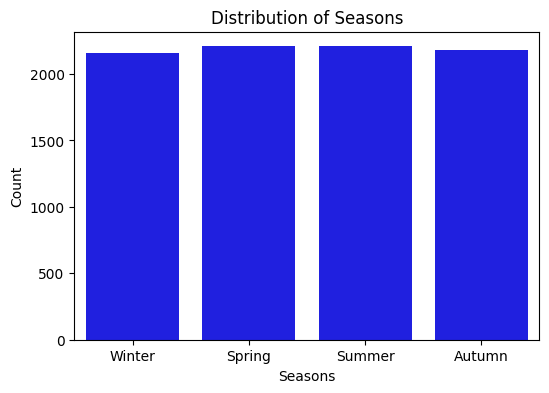

In [38]:
# رسم توزيع فصول السنة (Seasons)
plt.figure(figsize=(6, 4))
sns.countplot(data=df, x='Seasons', color='blue')
plt.title('Distribution of Seasons')
plt.xlabel('Seasons')
plt.ylabel('Count')
plt.show()

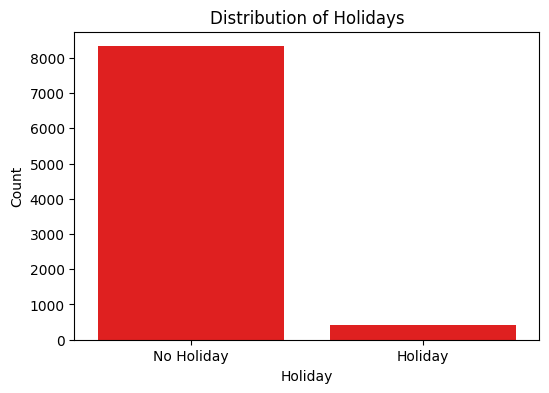

In [39]:
# رسم توزيع الإجازات (Holiday)
plt.figure(figsize=(6, 4))
sns.countplot(data=df, x='Holiday', color='red')
plt.title('Distribution of Holidays')
plt.xlabel('Holiday')
plt.ylabel('Count')
plt.show()

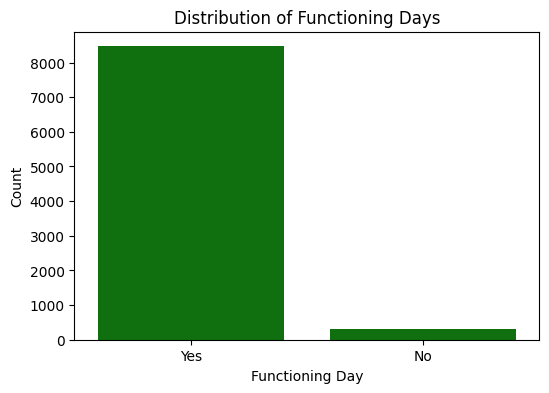

In [40]:
# رسم توزيع أيام التشغيل (Functioning Day)
plt.figure(figsize=(6, 4))
sns.countplot(data=df, x='Functioning Day', color='green')
plt.title('Distribution of Functioning Days')
plt.xlabel('Functioning Day')
plt.ylabel('Count')
plt.show()

In [43]:
# حساب متوسط الدراجات المؤجرة لكل المتغيرات الفئوية
print("=== Average Rented Bikes by Seasons ===")
print(df.groupby('Seasons')['Rented Bike Count'].mean().reset_index())

print("\n=== Average Rented Bikes by Holiday ===")
print(df.groupby('Holiday')['Rented Bike Count'].mean().reset_index())

print("\n=== Average Rented Bikes by Functioning Day ===")
print(df.groupby('Functioning Day')['Rented Bike Count'].mean().reset_index())

=== Average Rented Bikes by Seasons ===
  Seasons  Rented Bike Count
0  Autumn         819.597985
1  Spring         730.031250
2  Summer        1034.073370
3  Winter         225.541204

=== Average Rented Bikes by Holiday ===
      Holiday  Rented Bike Count
0     Holiday         499.756944
1  No Holiday         715.228026

=== Average Rented Bikes by Functioning Day ===
  Functioning Day  Rented Bike Count
0              No           0.000000
1             Yes         729.156999


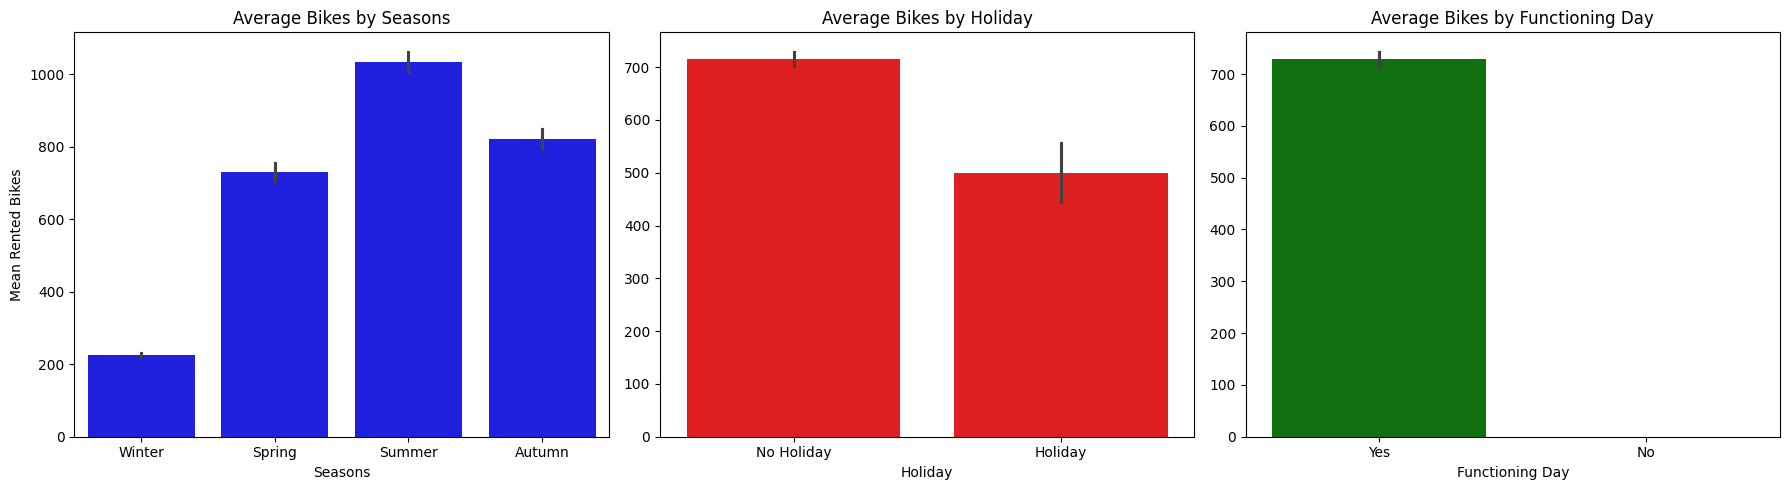

In [45]:
import matplotlib.pyplot as plt
import seaborn as sns

# إعداد نافذة الرسم لتشمل 3 رسومات بجانب بعضها أو تحت بعض
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# 1. متوسط الدراجات حسب الفصول
sns.barplot(data=df, x='Seasons', y='Rented Bike Count', ax=axes[0], color='blue')
axes[0].set_title('Average Bikes by Seasons')
axes[0].set_xlabel('Seasons')
axes[0].set_ylabel('Mean Rented Bikes')

# 2. متوسط الدراجات حسب الإجازات
sns.barplot(data=df, x='Holiday', y='Rented Bike Count', ax=axes[1], color='red')
axes[1].set_title('Average Bikes by Holiday')
axes[1].set_xlabel('Holiday')
axes[1].set_ylabel('')

# 3. متوسط الدراجات حسب أيام التشغيل
sns.barplot(data=df, x='Functioning Day', y='Rented Bike Count', ax=axes[2], color='green')
axes[2].set_title('Average Bikes by Functioning Day')
axes[2].set_xlabel('Functioning Day')
axes[2].set_ylabel('')

plt.tight_layout()
plt.show()

In [64]:
# حساب الإحصاءات الوصفية لعدد الدراجات المؤجرة (المتوسط والانحراف المعياري والربيعات) لكل فصل وفي أيام الإجازة
cat_analysis_seasons = df.groupby('Seasons')['Rented Bike Count'].agg(['count', 'mean', 'std', 'median', 'min', 'max'])
print("--- Detailed Statistics by Seasons ---")
display(cat_analysis_seasons)

cat_analysis_holiday = df.groupby('Holiday')['Rented Bike Count'].agg(['count', 'mean', 'std', 'median', 'min', 'max'])
print("\n--- Detailed Statistics by Holiday ---")
display(cat_analysis_holiday)

--- Detailed Statistics by Seasons ---


,count,mean,std,median,min,max
Seasons,,,,,,
Autumn,2184,819.597985,651.085621,763.5,0,3298
Spring,2208,730.031250,621.509635,583.0,0,3251
Summer,2208,1034.073370,690.244759,905.5,9,3556
Winter,2160,225.541204,150.372236,203.0,3,937



--- Detailed Statistics by Holiday ---


,count,mean,std,median,min,max
Holiday,,,,,,
Holiday,432,499.756944,570.772769,240.0,0,2400
No Holiday,8328,715.228026,646.879124,524.5,0,3556


## Numerical Variables

In [50]:
# استعراض الإحصاءات الوصفية للأعمدة الرقمية
numerical_summary = df.select_dtypes(include=['int64', 'float64']).describe().T
print(numerical_summary)

                            count         mean         std   min     25%  \
Rented Bike Count          8760.0   704.602055  644.997468   0.0  191.00   
Hour                       8760.0    11.500000    6.922582   0.0    5.75   
Temperature(°C)            8760.0    12.882922   11.944825 -17.8    3.50   
Humidity(%)                8760.0    58.226256   20.362413   0.0   42.00   
Wind speed (m/s)           8760.0     1.724909    1.036300   0.0    0.90   
Visibility (10m)           8760.0  1436.825799  608.298712  27.0  940.00   
Dew point temperature(°C)  8760.0     4.073813   13.060369 -30.6   -4.70   
Solar Radiation (MJ/m2)    8760.0     0.569111    0.868746   0.0    0.00   
Rainfall(mm)               8760.0     0.148687    1.128193   0.0    0.00   
Snowfall (cm)              8760.0     0.075068    0.436746   0.0    0.00   

                               50%      75%      max  
Rented Bike Count           504.50  1065.25  3556.00  
Hour                         11.50    17.25    23.00 

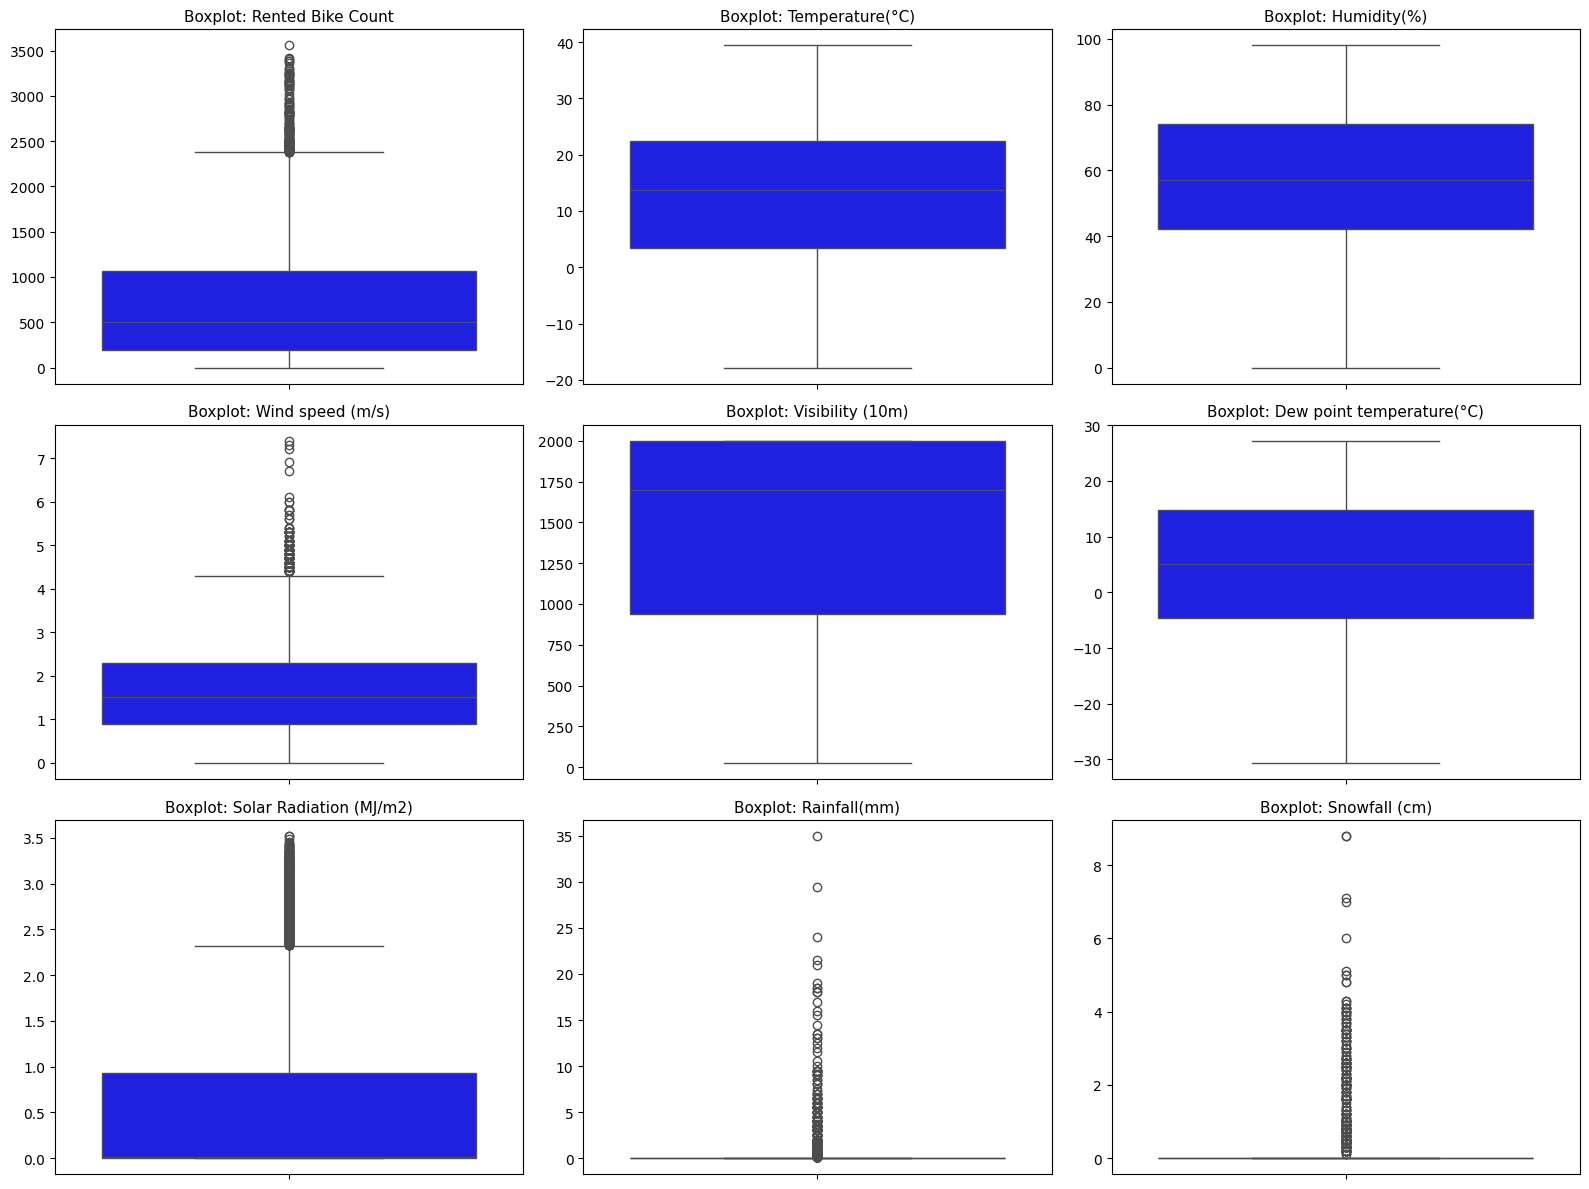

In [52]:
import matplotlib.pyplot as plt
import seaborn as sns

# اختيار الأعمدة الرقمية الأساسية
num_cols = ['Rented Bike Count', 'Temperature(°C)', 'Humidity(%)', 
            'Wind speed (m/s)', 'Visibility (10m)', 'Dew point temperature(°C)', 
            'Solar Radiation (MJ/m2)', 'Rainfall(mm)', 'Snowfall (cm)']

# رسم Boxplot لكل عمود رقمي لمعرفة القيم الشاذة
plt.figure(figsize=(16, 12))
for i, col in enumerate(num_cols, 1):
    plt.subplot(3, 3, i)
    sns.boxplot(data=df, y=col, color='blue')
    plt.title(f'Boxplot: {col}', fontsize=11)
    plt.ylabel('')
    
plt.tight_layout()
plt.show()

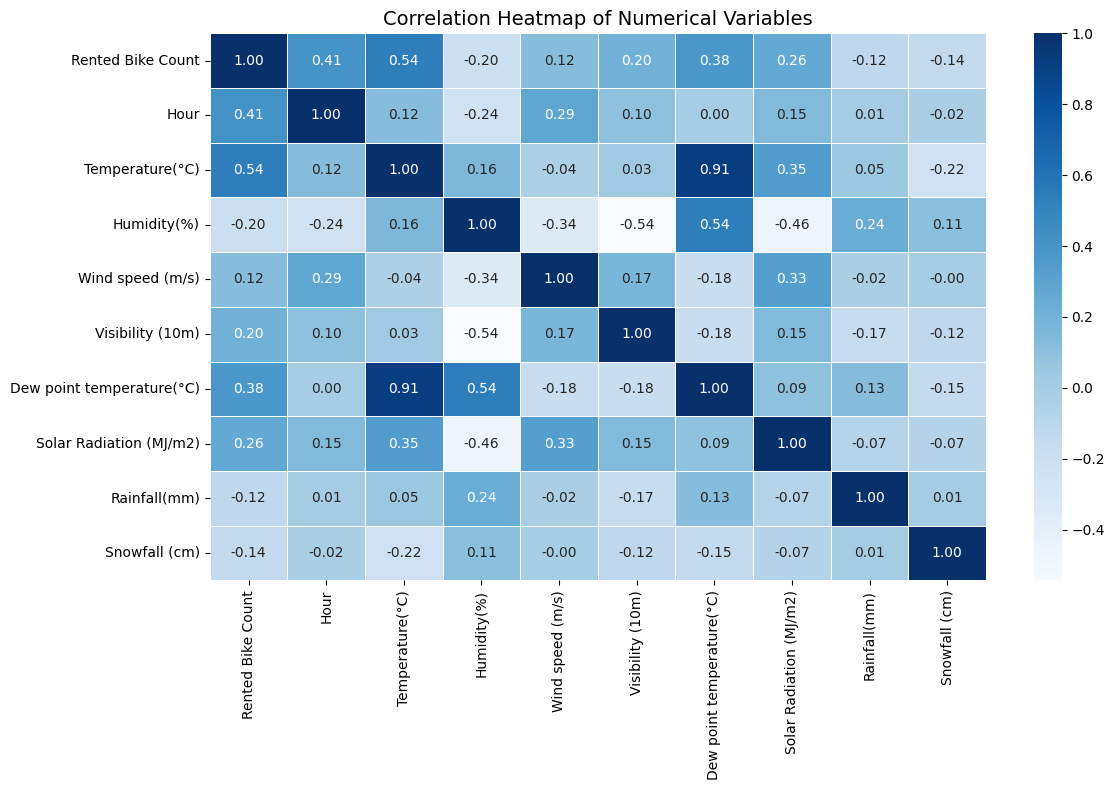

In [53]:
# حساب مصفوفة الارتباط ورسمها (Heatmap)
plt.figure(figsize=(12, 8))

# حساب الارتباط للأعمدة الرقمية فقط
corr_matrix = df.select_dtypes(include=['int64', 'float64']).corr()

# رسم الخريطة الحرارية
sns.heatmap(corr_matrix, annot=True, cmap='Blues', fmt='.2f', linewidths=0.5, cbar=True)
plt.title('Correlation Heatmap of Numerical Variables', fontsize=14)
plt.tight_layout()
plt.show()

In [70]:
# حساب معامل الانحراف (Skewness) لكل الأعمدة الرقمية لمعرفة مدى اعتدال توزيعها
num_cols_list = df.select_dtypes(include=['int64', 'float64']).columns
skewness_report = df[num_cols_list].skew().reset_index()
skewness_report.columns = ['Numerical Column', 'Skewness Value']
print("--- Skewness Report for Numerical Variables ---")
display(skewness_report)

--- Skewness Report for Numerical Variables ---


,Numerical Column,Skewness Value
0,Rented Bike Count,1.153428
1,Hour,0.000000
2,Temperature(°C),-0.198326
3,Humidity(%),0.059579
4,Wind speed (m/s),0.890955
5,Visibility (10m),-0.701786
6,Dew point temperature(°C),-0.367298
7,Solar Radiation (MJ/m2),1.504040
8,Rainfall(mm),14.533232
9,Snowfall (cm),8.440801


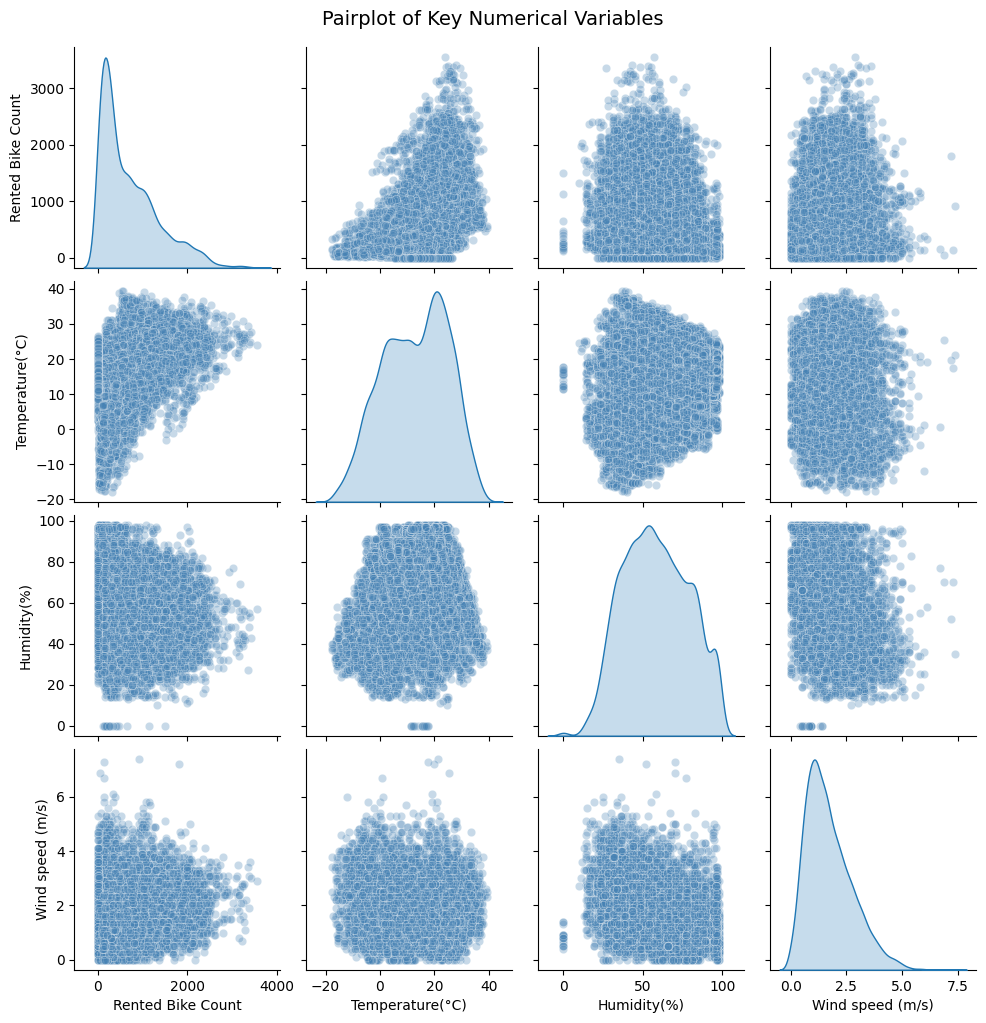

In [71]:
import matplotlib.pyplot as plt
import seaborn as sns

# رسم تباين سريع بين أهم الأعمدة الرقمية (درجة الحرارة، الرطوبة، سرعة الرياح، والهدف)
key_num_cols = ['Rented Bike Count', 'Temperature(°C)', 'Humidity(%)', 'Wind speed (m/s)']
sns.pairplot(df[key_num_cols], diag_kind='kde', plot_kws={'alpha': 0.3, 'color': 'steelblue'})
plt.suptitle('Pairplot of Key Numerical Variables', y=1.02, fontsize=14)
plt.show()

## Relationships between the features and the target

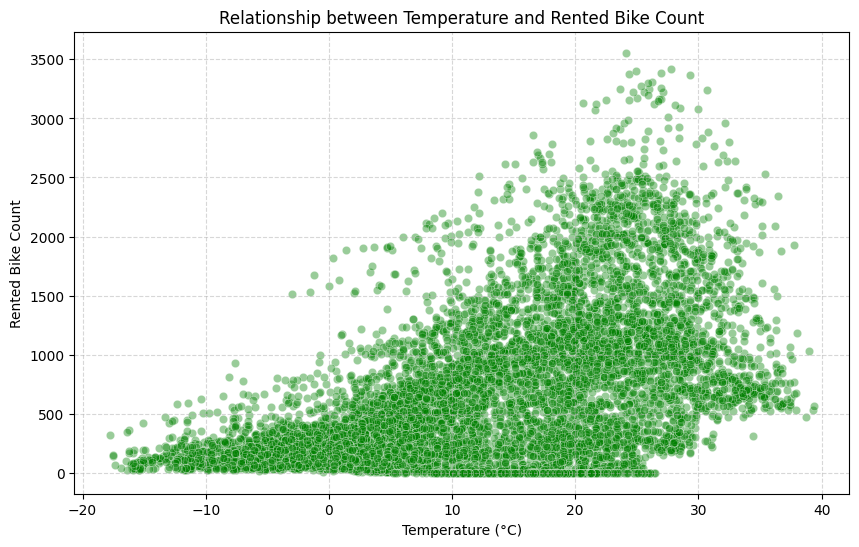

In [60]:
import matplotlib.pyplot as plt
import seaborn as sns

# العلاقة بين درجة الحرارة وعدد الدراجات المؤجرة
plt.figure(figsize=(10, 6))
sns.scatterplot(data=df, x='Temperature(°C)', y='Rented Bike Count', alpha=0.4, color='green')
plt.title('Relationship between Temperature and Rented Bike Count')
plt.xlabel('Temperature (°C)')
plt.ylabel('Rented Bike Count')
plt.grid(True, linestyle='--', alpha=0.5)
plt.show()

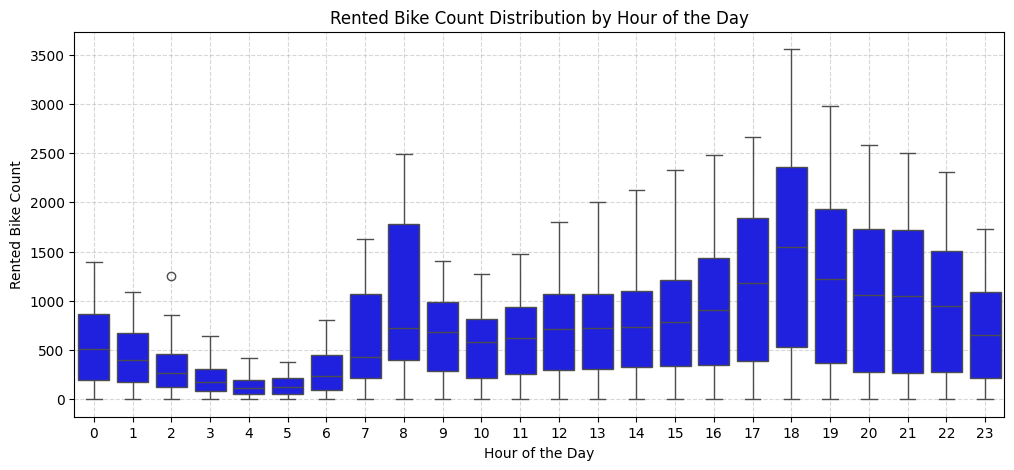

In [59]:
# العلاقة بين ساعات اليوم وعدد الدراجات المؤجرة (باستخدام Boxplot لتوضيح التوزيع لكل ساعة)
plt.figure(figsize=(12, 5))
sns.boxplot(data=df, x='Hour', y='Rented Bike Count', color='blue')
plt.title('Rented Bike Count Distribution by Hour of the Day')
plt.xlabel('Hour of the Day')
plt.ylabel('Rented Bike Count')
plt.grid(True, linestyle='--', alpha=0.5)
plt.show()

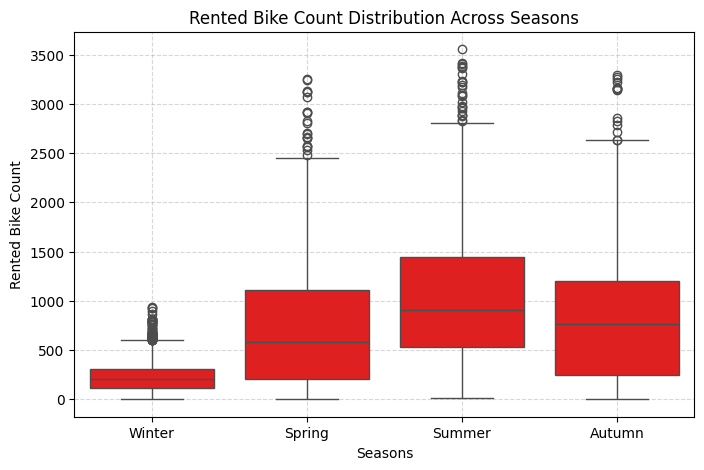

In [58]:
# العلاقة بين الفصول وعدد الدراجات المؤجرة
plt.figure(figsize=(8, 5))
sns.boxplot(data=df, x='Seasons', y='Rented Bike Count', color='red')
plt.title('Rented Bike Count Distribution Across Seasons')
plt.xlabel('Seasons')
plt.ylabel('Rented Bike Count')
plt.grid(True, linestyle='--', alpha=0.5)
plt.show()

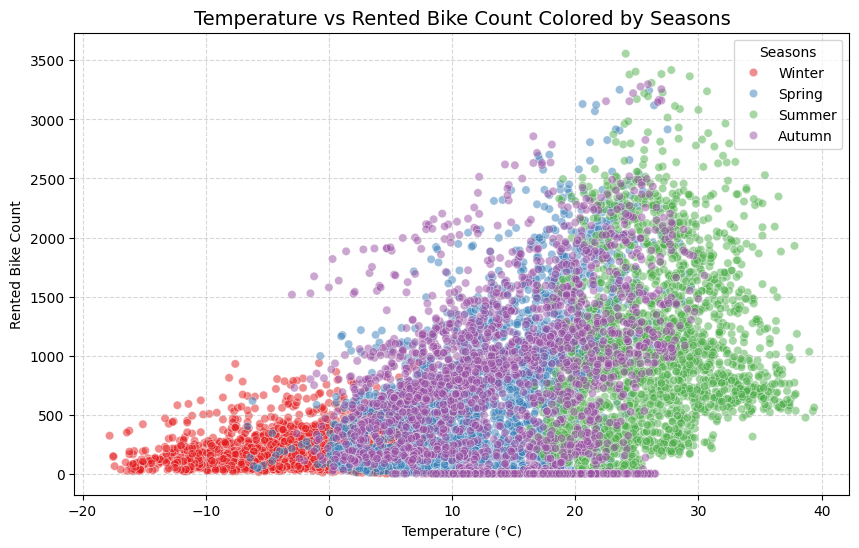

In [67]:
# العلاقة بين درجة الحرارة وعدد الدراجات مع تقسيمها حسب فصول السنة
plt.figure(figsize=(10, 6))
sns.scatterplot(data=df, x='Temperature(°C)', y='Rented Bike Count', hue='Seasons', palette='Set1', alpha=0.5)
plt.title('Temperature vs Rented Bike Count Colored by Seasons', fontsize=14)
plt.xlabel('Temperature (°C)')
plt.ylabel('Rented Bike Count')
plt.legend(title='Seasons')
plt.grid(True, linestyle='--', alpha=0.5)
plt.show()